# Day 80: Project 2 — Churn Prediction: Problem + EDA + Class Imbalance

## Objective
- Define the churn problem before touching the data
- Load and inspect the Telco Customer Churn data, check the churn rate
- Explore churn by contract type, tenure, and monthly charges
- Check the class imbalance and decide how much special handling it needs
- Visualize: violin plot of `MonthlyCharges` by churn, bar plot of churn rate by contract

> **Data:** the Telco Customer Churn sample dataset (7,043 customers, 21 columns), the same data as the Kaggle dataset.
> The file is not included in this folder. The notebook uses `data/` if it is there, otherwise it downloads a public copy.
> See `data/README.md`.

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import chi2_contingency
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

plt.style.use("seaborn-v0_8-darkgrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.titlesize": 14, "axes.titleweight": "bold", "axes.labelsize": 11})
STAY, CHURN = "#0072B2", "#D55E00"      # blue = stayed, orange = churned (color-blind safe)
Path("images").mkdir(exist_ok=True)

## 1. The problem (written before looking at the data)

**Business question:** a telecom company loses customers every month. If we can spot customers who are **likely to leave**, the retention team can reach out first (a call, an offer, a better plan).

| | |
|---|---|
| **Problem type** | Supervised **binary classification** |
| **Target** | `Churn` (Yes = the customer left, No = the customer stayed) |
| **Features** | account facts (contract, tenure, payment method), services (internet, phone, add-ons), and charges |
| **Not a feature** | `customerID` (a label, not information) |
| **Why accuracy is not enough** | Churners are the minority. A model that says "nobody will leave" can still look accurate |
| **Better metrics** | **Recall** (how many churners we catch), **precision** (how many of our flags are real), **F1**, and the area under the precision-recall curve |
| **The cost trade-off** | Missing a churner (false negative) loses a customer. Flagging a loyal customer (false positive) wastes a retention offer. Which matters more is a business decision, so we will tune the decision threshold later |
| **Validation** | The data is a single snapshot (no dates), so a **stratified** train/test split keeps the churn share the same in both parts |

## 2. Load the data

In [2]:
BASE = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

def load_telco():
    for name in ["WA_Fn-UseC_-Telco-Customer-Churn.csv", "Telco-Customer-Churn.csv"]:
        local = Path("data") / name
        if local.exists():
            return pd.read_csv(local)
    return pd.read_csv(BASE)

df = load_telco()
print(df.shape)

(7043, 21)


In [3]:
df.head(3).T

,0,1,2
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK
gender,Female,Male,Male
SeniorCitizen,0,0,0
Partner,Yes,No,No
Dependents,No,No,No
tenure,1,34,2
PhoneService,No,Yes,Yes
MultipleLines,No phone service,No,No
InternetService,DSL,DSL,DSL
OnlineSecurity,No,Yes,Yes


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 3. Inspect: duplicates, missing values, and one text-vs-number trap

In [5]:
print("Rows, columns:", df.shape)
print("Duplicate rows:", int(df.duplicated().sum()), "| duplicate customerIDs:", int(df["customerID"].duplicated().sum()))
print("Columns with missing values:", int(df.isna().any().sum()))

blank = df["TotalCharges"].str.strip() == ""
print("TotalCharges is stored as text. Blank values:", int(blank.sum()))
print("  those customers: tenure =", [int(t) for t in sorted(df.loc[blank, "tenure"].unique())],
      "| churn =", sorted(df.loc[blank, "Churn"].unique()))

Rows, columns: (7043, 21)
Duplicate rows: 0 | duplicate customerIDs: 0
Columns with missing values: 0
TotalCharges is stored as text. Blank values: 11
  those customers: tenure = [0] | churn = ['No']


In [6]:
# Fix the trap: blanks become NaN, and the column becomes numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["churned"] = (df["Churn"] == "Yes").astype(int)
print("TotalCharges is now", df["TotalCharges"].dtype, "with", int(df["TotalCharges"].isna().sum()), "missing values")

TotalCharges is now float64 with 11 missing values


In [7]:
# Values like 'No internet service' and 'No phone service' are real categories, not missing data
for col in ["MultipleLines", "OnlineSecurity", "InternetService"]:
    print(col, "->", sorted(df[col].unique()))

MultipleLines -> ['No', 'No phone service', 'Yes']
OnlineSecurity -> ['No', 'No internet service', 'Yes']
InternetService -> ['DSL', 'Fiber optic', 'No']


## 4. Churn rate and class imbalance

In [8]:
counts = df["Churn"].value_counts()
share = df["Churn"].value_counts(normalize=True)
print(pd.DataFrame({"customers": counts, "share": share.round(3)}).to_string())
print("Always predict 'No': accuracy", round(share["No"], 3), "| churners caught: 0 of", counts["Yes"])
print("Imbalance ratio (No : Yes) =", round(counts["No"] / counts["Yes"], 2), ": 1")

       customers  share
Churn                  
No          5174  0.735
Yes         1869  0.265
Always predict 'No': accuracy 0.735 | churners caught: 0 of 1869
Imbalance ratio (No : Yes) = 2.77 : 1


**Reading it:** about 26.5% of customers churned, close to the ~26% the roadmap expects.
The split is about 73.5 / 26.5. That is just past the 70 / 30 line, so it needs **some** care, but it is a moderate imbalance, not an extreme one.
What it means for the next days: use a **stratified** split, judge models with recall, precision, F1, and PR-AUC (not accuracy), and try **class weights** (for example `scale_pos_weight` in XGBoost, about the ratio above) and **threshold tuning** before reaching for resampling tricks.

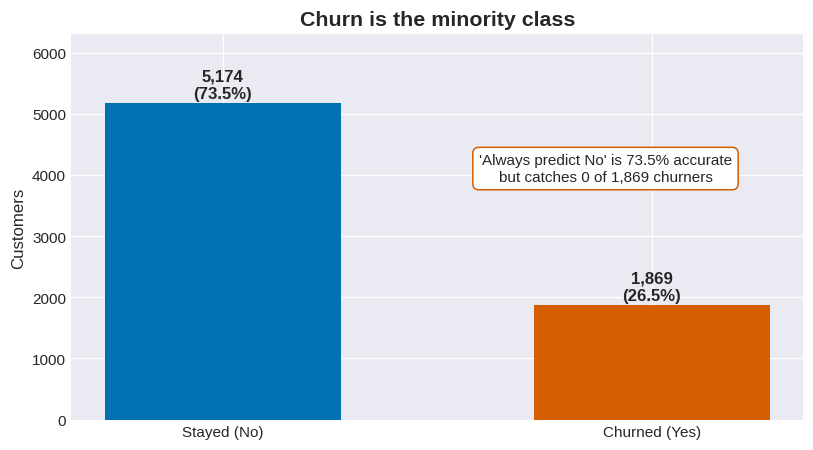

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
bars = ax.bar(["Stayed (No)", "Churned (Yes)"], [counts["No"], counts["Yes"]], color=[STAY, CHURN], width=0.55)
for bar, key in zip(bars, ["No", "Yes"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 80,
            f"{counts[key]:,}\n({share[key]:.1%})", ha="center", fontsize=11, fontweight="bold")
ax.set_ylim(0, 6300)
ax.set_title("Churn is the minority class")
ax.set_ylabel("Customers")
ax.text(0.73, 0.62, f"'Always predict No' is {share['No']:.1%} accurate\nbut catches 0 of {counts['Yes']:,} churners",
        transform=ax.transAxes, ha="center", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor=CHURN))
plt.tight_layout()
plt.savefig("images/class_balance.png")
plt.show()

## 5. Churn by contract type

In [10]:
by_contract = df.groupby("Contract")["churned"].agg(customers="size", churn_rate="mean")
by_contract["churn_rate"] = (by_contract["churn_rate"] * 100).round(1)
print(by_contract.sort_values("churn_rate", ascending=False).to_string())

                customers  churn_rate
Contract                             
Month-to-month       3875        42.7
One year             1473        11.3
Two year             1695         2.8


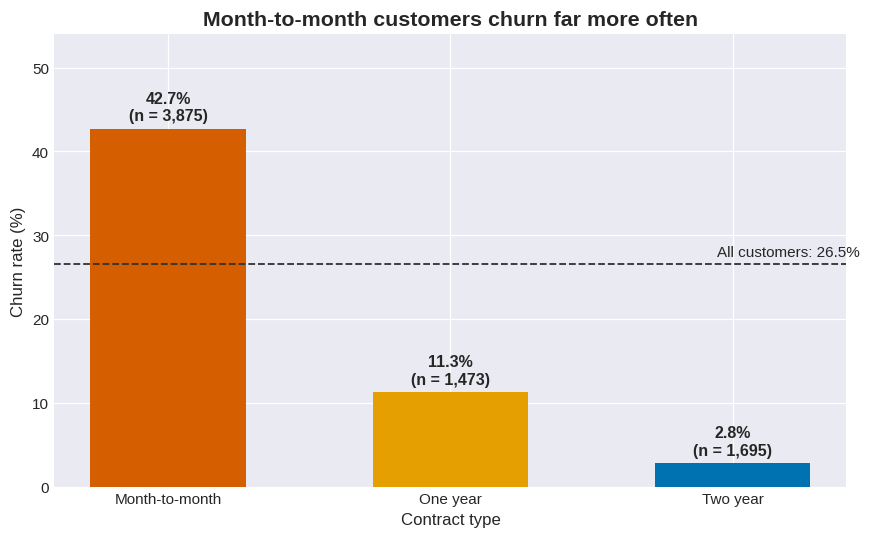

In [11]:
order = by_contract.sort_values("churn_rate", ascending=False)
overall = df["churned"].mean() * 100

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(order.index, order["churn_rate"], color=[CHURN, "#E69F00", STAY], width=0.55)
for bar, (name, row) in zip(bars, order.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2, row["churn_rate"] + 1,
            f"{row['churn_rate']:.1f}%\n(n = {int(row['customers']):,})", ha="center", fontsize=10.5, fontweight="bold")
ax.axhline(overall, color="#333333", linestyle="--", linewidth=1.2)
ax.text(2.45, overall + 1, f"All customers: {overall:.1f}%", ha="right", fontsize=10)
ax.set_ylim(0, 54)
ax.set_title("Month-to-month customers churn far more often")
ax.set_xlabel("Contract type")
ax.set_ylabel("Churn rate (%)")
plt.tight_layout()
plt.savefig("images/churn_by_contract.png")
plt.show()

## 6. Churn by tenure

In [12]:
df["tenure_group"] = pd.cut(df["tenure"], [-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])
by_tenure = df.groupby("tenure_group", observed=True)["churned"].agg(customers="size", churn_rate="mean")
by_tenure["churn_rate"] = (by_tenure["churn_rate"] * 100).round(1)
print("Churn rate by tenure (months):")
print(by_tenure.to_string())
print("Median tenure: stayed", int(df.loc[df["churned"] == 0, "tenure"].median()),
      "months | churned", int(df.loc[df["churned"] == 1, "tenure"].median()), "months")

Churn rate by tenure (months):
              customers  churn_rate
tenure_group                       
0-12               2186        47.4
13-24              1024        28.7
25-48              1594        20.4
49-72              2239         9.5
Median tenure: stayed 38 months | churned 10 months


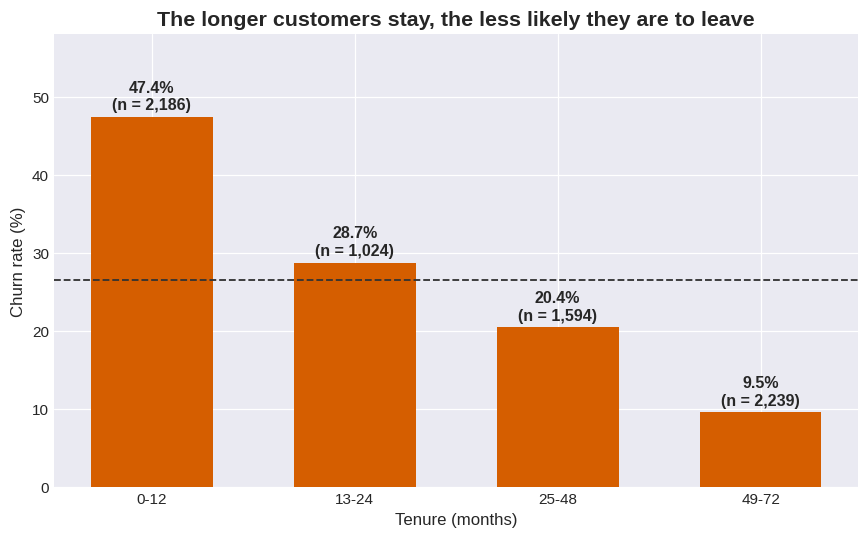

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(by_tenure.index.astype(str), by_tenure["churn_rate"], color=CHURN, width=0.6)
for bar, (name, row) in zip(bars, by_tenure.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2, row["churn_rate"] + 1,
            f"{row['churn_rate']:.1f}%\n(n = {int(row['customers']):,})", ha="center", fontsize=10.5, fontweight="bold")
ax.axhline(overall, color="#333333", linestyle="--", linewidth=1.2)
ax.set_ylim(0, 58)
ax.set_title("The longer customers stay, the less likely they are to leave")
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Churn rate (%)")
plt.tight_layout()
plt.savefig("images/churn_by_tenure.png")
plt.show()

## 7. Monthly charges

In [14]:
print(df.groupby("Churn")["MonthlyCharges"].agg(["mean", "median"]).round(1).to_string())

       mean  median
Churn              
No     61.3    64.4
Yes    74.4    79.6


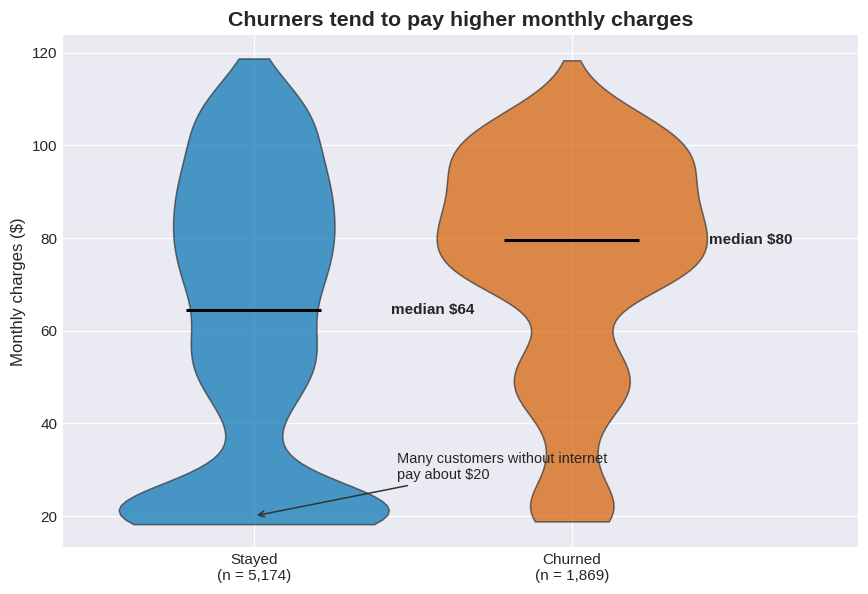

In [15]:
stay = df.loc[df["churned"] == 0, "MonthlyCharges"]
gone = df.loc[df["churned"] == 1, "MonthlyCharges"]

fig, ax = plt.subplots(figsize=(8, 5.5))
parts = ax.violinplot([stay, gone], positions=[1, 2], showmedians=True, showextrema=False, widths=0.85)
for body, color in zip(parts["bodies"], [STAY, CHURN]):
    body.set_facecolor(color)
    body.set_edgecolor("#333333")
    body.set_alpha(0.7)
parts["cmedians"].set_color("black")
parts["cmedians"].set_linewidth(2)
for pos, data in zip([1, 2], [stay, gone]):
    ax.text(pos + 0.43, data.median(), f"median ${data.median():.0f}", va="center", fontsize=10, fontweight="bold")
ax.annotate("Many customers without internet\npay about $20", xy=(1, 20), xytext=(1.45, 28), fontsize=9.5,
            arrowprops=dict(arrowstyle="->", color="#333333"))
ax.set_xticks([1, 2])
ax.set_xticklabels([f"Stayed\n(n = {len(stay):,})", f"Churned\n(n = {len(gone):,})"])
ax.set_xlim(0.4, 2.9)
ax.set_title("Churners tend to pay higher monthly charges")
ax.set_ylabel("Monthly charges ($)")
plt.tight_layout()
plt.savefig("images/monthly_charges_violin.png")
plt.show()

Churners pay more on average. But before reading that as "higher bills cause churn", check whether something else explains it.
Internet service type is a suspect: fiber optic costs more, and may also churn more.

In [16]:
df["charge_quartile"] = pd.qcut(df["MonthlyCharges"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
overall_q = (df.groupby("charge_quartile", observed=True)["churned"].mean() * 100).round(1)
print("Overall churn rate (%) by monthly-charge quartile:")
print(overall_q.to_string())

within = pd.crosstab(df["InternetService"], df["charge_quartile"], values=df["churned"], aggfunc="mean") * 100
print("Within each internet service (%):")
print(within.round(1).to_string())
print("Average monthly charge by service:", df.groupby("InternetService")["MonthlyCharges"].mean().round(1).to_dict())

Overall churn rate (%) by monthly-charge quartile:
charge_quartile
Q1 (lowest)     11.2
Q2              24.6
Q3              37.5
Q4 (highest)    32.9
Within each internet service (%):
charge_quartile  Q1 (lowest)    Q2    Q3  Q4 (highest)
InternetService                                       
DSL                     36.0  21.1   6.4           2.0
Fiber optic              NaN  59.0  50.9          33.8
No                       7.4   NaN   NaN           NaN
Average monthly charge by service: {'DSL': 58.1, 'Fiber optic': 91.5, 'No': 21.1}


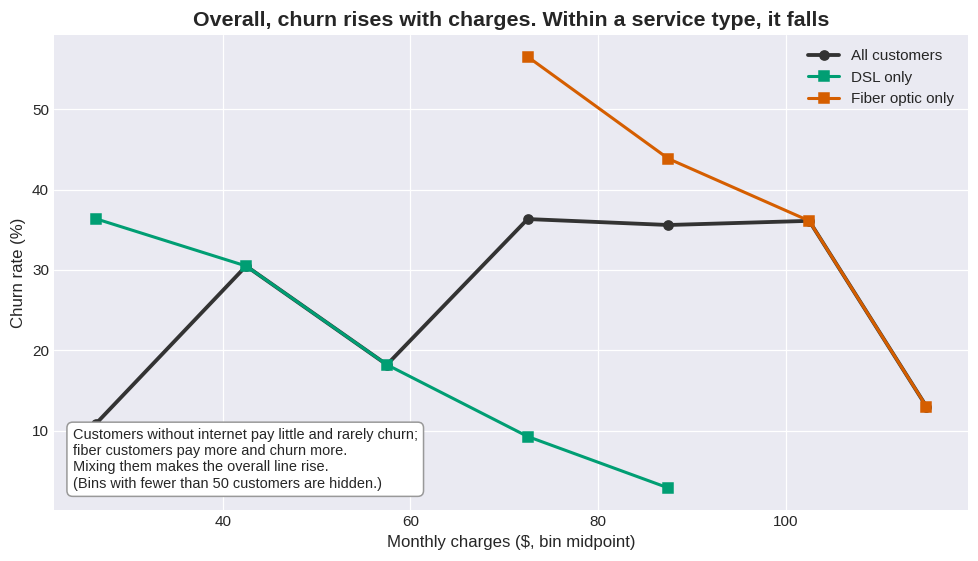

In [17]:
bins = [18, 35, 50, 65, 80, 95, 110, 120]
df["charge_bin"] = pd.cut(df["MonthlyCharges"], bins)

fig, ax = plt.subplots(figsize=(9, 5.2))
all_rate = df.groupby("charge_bin", observed=True)["churned"].mean() * 100
mid = [iv.mid for iv in all_rate.index]
ax.plot(mid, all_rate.values, color="#333333", linewidth=2.5, marker="o", label="All customers")
for service, color in [("DSL", "#009E73"), ("Fiber optic", CHURN)]:
    sub = df[df["InternetService"] == service]
    g = sub.groupby("charge_bin", observed=True)["churned"].agg(["mean", "size"])
    g = g[g["size"] >= 50]
    ax.plot([iv.mid for iv in g.index], g["mean"] * 100, color=color, linewidth=2, marker="s", label=service + " only")
ax.set_title("Overall, churn rises with charges. Within a service type, it falls")
ax.set_xlabel("Monthly charges ($, bin midpoint)")
ax.set_ylabel("Churn rate (%)")
ax.text(0.02, 0.04, "Customers without internet pay little and rarely churn;\nfiber customers pay more and churn more.\nMixing them makes the overall line rise.\n(Bins with fewer than 50 customers are hidden.)",
        transform=ax.transAxes, fontsize=9.5, va="bottom",
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#999999"))
ax.legend()
plt.tight_layout()
plt.savefig("images/churn_vs_charges_by_internet.png")
plt.show()

## 8. Is the contract effect just a tenure effect?

In [18]:
rate = pd.crosstab(df["Contract"], df["tenure_group"], values=df["churned"], aggfunc="mean")
n = pd.crosstab(df["Contract"], df["tenure_group"])
cell = (rate * 100).round(1).astype(str) + "% (" + n.astype(str) + ")"
print("Churn rate (customers) by contract and tenure (months):")
print(cell.to_string())

Churn rate (customers) by contract and tenure (months):
tenure_group            0-12        13-24        25-48        49-72
Contract                                                           
Month-to-month  51.4% (1994)  37.7% (737)  32.9% (802)  26.0% (342)
One year         10.5% (124)   8.1% (197)  10.6% (518)  12.9% (634)
Two year           0.0% (68)    0.0% (90)   2.2% (274)  3.3% (1263)


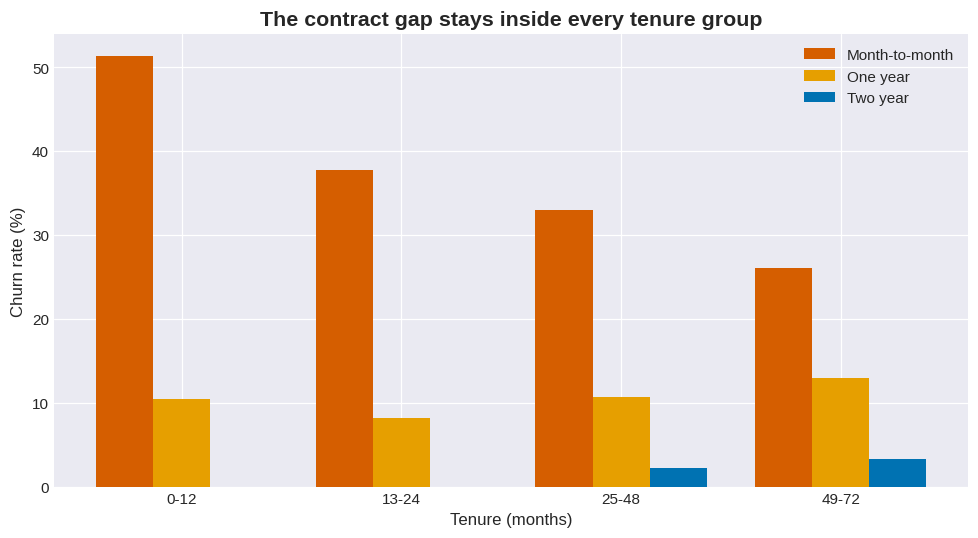

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
width = 0.26
x = np.arange(4)
colors = {"Month-to-month": CHURN, "One year": "#E69F00", "Two year": STAY}
for i, contract in enumerate(["Month-to-month", "One year", "Two year"]):
    ax.bar(x + (i - 1) * width, rate.loc[contract] * 100, width, color=colors[contract], label=contract)
ax.set_xticks(x)
ax.set_xticklabels(rate.columns.astype(str))
ax.set_title("The contract gap stays inside every tenure group")
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Churn rate (%)")
ax.legend()
plt.tight_layout()
plt.savefig("images/contract_by_tenure.png")
plt.show()

Month-to-month customers churn more than one-year and two-year customers in **every** tenure group, so the contract link is not only a tenure effect.
Some cells are small (two-year contracts in the 0-12 group have 68 customers), so those rates are rough.

## 9. Which features are most associated with churn?

In [20]:
cat_cols = [c for c in df.select_dtypes(include=["object", "string", "category"]).columns
            if c not in ("customerID", "Churn", "tenure_group", "charge_quartile", "charge_bin")] + ["SeniorCitizen"]

rows = []
for col in cat_cols:
    table = pd.crosstab(df[col], df["Churn"])
    chi2, p, _, _ = chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    rates = df.groupby(col, observed=True)["churned"].mean() * 100
    rows.append({"feature": col, "cramers_v": cramers_v, "p_value": p, "rate_gap_pts": rates.max() - rates.min()})

assoc = pd.DataFrame(rows).sort_values("cramers_v", ascending=False).reset_index(drop=True)
print(assoc.head(8).assign(p_value=lambda t: t["p_value"].map("{:.1e}".format)).round(3).to_string(index=False))

         feature  cramers_v  p_value  rate_gap_pts
        Contract      0.410 5.9e-258        39.878
  OnlineSecurity      0.347 2.7e-185        34.362
     TechSupport      0.343 1.4e-180        34.230
 InternetService      0.322 9.6e-160        34.488
   PaymentMethod      0.303 3.7e-140        30.042
    OnlineBackup      0.292 2.1e-131        32.524
DeviceProtection      0.282 5.5e-122        31.723
 StreamingMovies      0.231  2.7e-82        26.275


Cramer's V runs from 0 (no association) to 1 (perfect association). With 7,043 customers, even weak links give tiny p-values (strong evidence against independence),
so the **size** of V and the churn-rate gap matter more than the p-value.

In [21]:
print("Correlation of each number with churn (1 = churned):")
num = df[["tenure", "MonthlyCharges", "TotalCharges", "churned"]].corr()["churned"].drop("churned").round(3)
print(num.to_string())

Correlation of each number with churn (1 = churned):
tenure           -0.352
MonthlyCharges    0.193
TotalCharges     -0.199


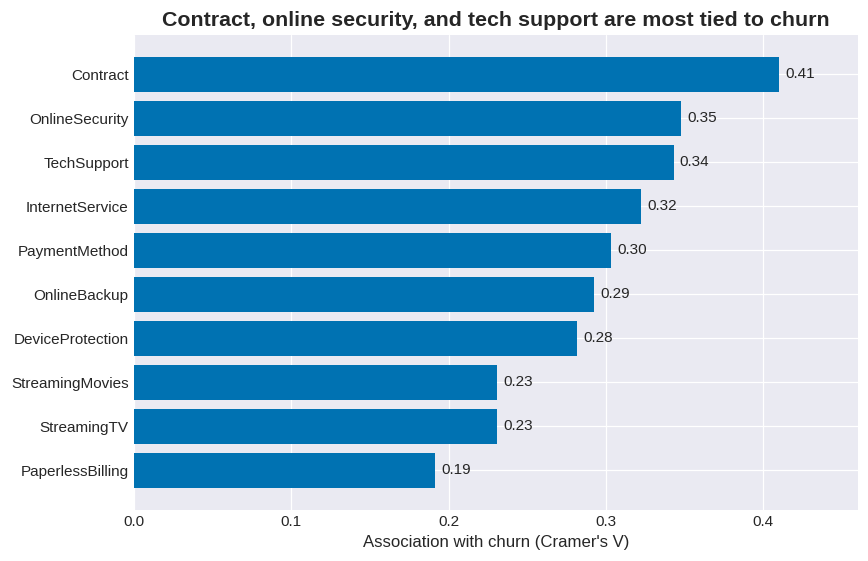

In [22]:
top = assoc.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(top["feature"], top["cramers_v"], color=STAY)
for y, v in enumerate(top["cramers_v"]):
    ax.text(v + 0.004, y, f"{v:.2f}", va="center", fontsize=10)
ax.set_title("Contract, online security, and tech support are most tied to churn")
ax.set_xlabel("Association with churn (Cramer's V)")
ax.set_xlim(0, top["cramers_v"].max() + 0.05)
plt.tight_layout()
plt.savefig("images/feature_association.png")
plt.show()

## 10. Simple rule baselines (the bar for the models)

In [23]:
y = df["churned"]
month_to_month = df["Contract"] == "Month-to-month"
rules = {
    "Always predict No": np.zeros(len(df), dtype=int),
    "Month-to-month contract": month_to_month.astype(int),
    "Month-to-month and tenure <= 12": (month_to_month & (df["tenure"] <= 12)).astype(int),
}

rows = []
for name, pred in rules.items():
    rows.append({
        "rule": name,
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred),
        "f1": f1_score(y, pred),
        "flagged": int(pred.sum()),
    })
print(pd.DataFrame(rows).set_index("rule").round(3).to_string())

                                 accuracy  precision  recall     f1  flagged
rule                                                                        
Always predict No                   0.735      0.000   0.000  0.000        0
Month-to-month contract             0.654      0.427   0.886  0.576     3875
Month-to-month and tenure <= 12     0.742      0.514   0.548  0.530     1994


**Reading it:** "Month-to-month" flags 3,875 customers and catches 88.6% of churners, but only 42.7% of those flags are real, and its **accuracy (0.654) is lower than always saying No (0.735)**.
That is why accuracy is the wrong yardstick here. A model has to beat these rules on precision and recall, not on accuracy.

## Practice Exercise
Compare churn rates by `InternetService` and by `PaymentMethod`. Which group stands out?

In [24]:
for col in ["InternetService", "PaymentMethod"]:
    t = df.groupby(col)["churned"].agg(customers="size", churn_rate="mean")
    t["churn_rate"] = (t["churn_rate"] * 100).round(1)
    print(t.sort_values("churn_rate", ascending=False).to_string())
    print()

                 customers  churn_rate
InternetService                       
Fiber optic           3096        41.9
DSL                   2421        19.0
No                    1526         7.4

                           customers  churn_rate
PaymentMethod                                   
Electronic check                2365        45.3
Mailed check                    1612        19.1
Bank transfer (automatic)       1544        16.7
Credit card (automatic)         1522        15.2



## Mini Challenge
Find the 5 highest-churn customer segments (contract + internet service + payment method) that have at least 100 customers.

In [25]:
seg = df.groupby(["Contract", "InternetService", "PaymentMethod"])["churned"].agg(customers="size", churn_rate="mean").reset_index()
seg = seg[seg["customers"] >= 100].sort_values("churn_rate", ascending=False).head(5)
seg["churn_rate"] = (seg["churn_rate"] * 100).round(1)
print(seg.to_string(index=False))

      Contract InternetService             PaymentMethod  customers  churn_rate
Month-to-month     Fiber optic          Electronic check       1307        60.4
Month-to-month     Fiber optic              Mailed check        201        50.7
Month-to-month     Fiber optic Bank transfer (automatic)        327        45.6
Month-to-month     Fiber optic   Credit card (automatic)        293        41.6
Month-to-month             DSL          Electronic check        474        40.5


## EDA findings
- 7,043 customers, no duplicates, no missing values, but `TotalCharges` is text with 11 blanks (all new customers with tenure 0), which must be fixed
- Churn rate 26.5%, an imbalance of about 2.8 : 1, just past the 70/30 line: needs stratification, the right metrics, and class weights or threshold tuning
- Contract type has the strongest link: 42.7% (month-to-month) vs 11.3% (one year) vs 2.8% (two year), and the gap holds within every tenure group
- Churn falls as tenure grows (47.4% for 0-12 months down to 9.5% for 49-72 months)
- Churners pay more on average, but within an internet service type, higher charges go with **lower** churn, so monthly charges are tangled up with the service type
- Simple rules give the bar to beat: "month-to-month" catches 88.6% of churners with 42.7% precision
- Everything here is an **association**, not proof of cause

## Summary
- Defined the churn problem, the metrics, and the validation plan before modeling
- Found the imbalance (73.5 / 26.5) and what it means for evaluation
- Found that contract and tenure are strongly linked to churn, and that monthly charges are confounded by internet service
- Set rule-based baselines for the models to beat
- Next: Day 81, feature engineering and preprocessing (fix TotalCharges, encode, pipeline with class weights)